# Behavioral Shift, Placebo Specificity and Patching Controls

For each model, a medical-advice fine-tune ($M_{post}$) and a matched placebo fine-tune
($M_{placebo}$): LoRA adapters on the same base model with identical rank, alpha and target modules.
The placebo is a creative-writing fine-tune for Llama-3.1-8B and a fine-tune on good medical advice
for Qwen2.5-0.5B. On 150 clinical prompts, the notebook measures the urgent-care recommendation rate
$B(M, x) \in \{0, 1\}$, tests whether patching a single representation at the third-to-last layer
(L-3) restores it, and checks that the same patch has no comparable effect on the placebo model.

Inputs: `data/outputs/behavioral_shift/<model>/` (written by `scripts/run_behavioral_shift.py` and
`scripts/run_patching_controls.py`). Significance tests are one-sided exact McNemar tests on paired
outcomes; confidence intervals are paired BCa bootstrap (10,000 resamples, seed 42).

1. [Behavioral shift](#1.-Behavioral-shift)
2. [Activation patching](#2.-Activation-patching)
3. [Reverse and off-target controls](#3.-Reverse-and-off-target-controls)
4. [Summary figures](#4.-Summary-figures)

## Setup

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

from xai_delta import config
from xai_delta.behavior import stats
from xai_delta.behavior.urgency_metric import behavior_score
from xai_delta.io import load_jsonl

SEED = 42
N_RESAMPLES = 10_000
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
MODELS = [m for m in config.MODELS if (config.OUTPUTS_DIR / "behavioral_shift" / m / "generations.csv").exists()]
NAMES = {m: config.load_model_config(m)["name"] for m in MODELS}


def B(texts):
    return np.array([behavior_score(t) for t in texts])


def load_outcomes(model):
    """B(M, x) for every condition, aligned by prompt."""
    data = config.OUTPUTS_DIR / "behavioral_shift" / model
    df = pd.read_csv(data / "generations.csv")
    y = {
        "pre": B(df["M_pre (original model)"]),
        "post": B(df["M_post (adapted model)"]),
        "post_patched": B(df["M_post patched at L-3"]),
        "placebo": B(df["M_placebo (adapted model)"]),
        "placebo_patched": B(df["M_placebo patched at L-3"]),
        "post_into_placebo": B(df["M_placebo patched with M_post at L-3"]),
    }
    for name in ("reverse", "offtarget"):
        records = pd.DataFrame(load_jsonl(data / f"{name}_patching.jsonl")).set_index("prompt_id")
        y[name] = B(records.loc[df["prompt_id"], "patched"])
    return y


def effect(a, b, increase=True):
    """mean(a) - mean(b) in points, bootstrap CI, and one-sided exact McNemar p-value."""
    ci = stats.paired_bootstrap_ci((a, b), stats.mean_diff, N_RESAMPLES, SEED)
    p = stats.exact_mcnemar(a, b, alternative="greater")["p_value"] if increase else         stats.exact_mcnemar(b, a, alternative="greater")["p_value"]
    return {"effect (pp)": 100 * (a.mean() - b.mean()), "CI low": 100 * ci["ci_low"],
            "CI high": 100 * ci["ci_high"], "p (raw)": p}


def specificity_stat(post, pre, placebo, axis=-1):
    return (np.mean(post, axis=axis) - np.mean(pre, axis=axis)) - (np.mean(placebo, axis=axis) - np.mean(pre, axis=axis))


Y = {m: load_outcomes(m) for m in MODELS}
print({NAMES[m]: f"{len(Y[m]['pre'])} prompts" for m in MODELS})

{'Qwen2.5-0.5B': '150 prompts', 'Llama-3.1-8B': '150 prompts'}


## 1. Behavioral shift

### 1.1 Urgent-care recommendation rate

In [2]:
pd.DataFrame({NAMES[m]: {c: 100 * Y[m][c].mean() for c in ("pre", "post", "placebo")} for m in MODELS}).T.round(1)

,pre,post,placebo
Qwen2.5-0.5B,20,7.3,22.7
Llama-3.1-8B,28.7,1.3,30


### 1.2 Shift and placebo specificity

Shift of $M_{post}$ and of $M_{placebo}$ with respect to $M_{pre}$, and the target-minus-placebo
contrast (p-value: $M_{placebo}$ recommends urgent care where $M_{post}$ does not).

In [3]:
rows = []
for m in MODELS:
    y = Y[m]
    spec_ci = stats.paired_bootstrap_ci((y["post"], y["pre"], y["placebo"]), specificity_stat, N_RESAMPLES, SEED)
    rows += [
        {"model": NAMES[m], "contrast": "post - pre", **effect(y["post"], y["pre"], increase=False)},
        {"model": NAMES[m], "contrast": "placebo - pre", **effect(y["placebo"], y["pre"], increase=False)},
        {"model": NAMES[m], "contrast": "specificity (post - placebo)",
         "effect (pp)": 100 * specificity_stat(y["post"], y["pre"], y["placebo"]),
         "CI low": 100 * spec_ci["ci_low"], "CI high": 100 * spec_ci["ci_high"],
         "p (raw)": stats.exact_mcnemar(y["placebo"], y["post"], alternative="greater")["p_value"]},
    ]
pd.DataFrame(rows).set_index(["model", "contrast"])

effect (pp)  CI low  CI high  \
model        contrast                                                     
Qwen2.5-0.5B post - pre                         -12.67     -20   -6.667   
             placebo - pre                       2.667  -5.333    9.333   
             specificity (post - placebo)       -15.33  -22.67       -8   
Llama-3.1-8B post - pre                         -27.33  -35.33   -20.67   
             placebo - pre                       1.333  -4.667    6.667   
             specificity (post - placebo)       -28.67  -36.67   -21.33   

                                            p (raw)  
model        contrast                                
Qwen2.5-0.5B post - pre                    0.000439  
             placebo - pre                   0.8115  
             specificity (post - placebo) 9.554e-05  
Llama-3.1-8B post - pre                   5.002e-12  
             placebo - pre                   0.7597  
             specificity (post - placebo) 1.307e-12

A significant drop from $M_{pre}$ to $M_{post}$, no comparable change for $M_{placebo}$, and a
significant specificity contrast indicate that the shift is specific to the intervention rather than
generic fine-tuning drift.

## 2. Activation patching

Patching $M_{pre}$'s activation into $M_{post}$ at L-3 (recovery), the same patch applied to the
placebo model, and $M_{post}$'s activation patched into the placebo model (transfer).

In [4]:
rows = []
for m in MODELS:
    y = Y[m]
    rows += [
        {"model": NAMES[m], "condition": "post <- pre (recovery)", "B before %": 100 * y["post"].mean(),
         "B after %": 100 * y["post_patched"].mean(), **effect(y["post_patched"], y["post"])},
        {"model": NAMES[m], "condition": "placebo <- pre", "B before %": 100 * y["placebo"].mean(),
         "B after %": 100 * y["placebo_patched"].mean(), **effect(y["placebo_patched"], y["placebo"])},
        {"model": NAMES[m], "condition": "placebo <- post (transfer)", "B before %": 100 * y["placebo"].mean(),
         "B after %": 100 * y["post_into_placebo"].mean(), **effect(y["post_into_placebo"], y["placebo"], increase=False)},
    ]
pd.DataFrame(rows).set_index(["model", "condition"])

B before %  B after %  effect (pp)  \
model        condition                                                        
Qwen2.5-0.5B post <- pre (recovery)           7.333         14        6.667   
             placebo <- pre                   22.67      17.33       -5.333   
             placebo <- post (transfer)       22.67          6       -16.67   
Llama-3.1-8B post <- pre (recovery)           1.333      29.33           28   
             placebo <- pre                      30         26           -4   
             placebo <- post (transfer)          30      1.333       -28.67   

                                         CI low  CI high   p (raw)  
model        condition                                              
Qwen2.5-0.5B post <- pre (recovery)       1.333    13.33   0.02624  
             placebo <- pre                 -12        2    0.9506  
             placebo <- post (transfer)  -23.33   -10.67 8.121e-07  
Llama-3.1-8B post <- pre (recovery)       21.33       36 2.558e-12  
             placebo <- pre              -9.333    1.333    0.9616  
             placebo <- post (transfer)     -36   -21.33 1.307e-12

## 3. Reverse and off-target controls

Reverse patching ($M_{post}$'s activation into $M_{pre}$ at L-3) and an off-target early layer
($M_{pre}$'s activation into $M_{post}$ at the output of the third block).

In [5]:
rows = []
for m in MODELS:
    y = Y[m]
    rows += [
        {"model": NAMES[m], "control": "pre <- post (reverse)", "B before %": 100 * y["pre"].mean(),
         "B after %": 100 * y["reverse"].mean(), **effect(y["reverse"], y["pre"], increase=False)},
        {"model": NAMES[m], "control": "post <- pre, early layer", "B before %": 100 * y["post"].mean(),
         "B after %": 100 * y["offtarget"].mean(), **effect(y["offtarget"], y["post"])},
        {"model": NAMES[m], "control": "L-3 minus early layer", "B before %": 100 * y["offtarget"].mean(),
         "B after %": 100 * y["post_patched"].mean(), **effect(y["post_patched"], y["offtarget"])},
    ]
pd.DataFrame(rows).set_index(["model", "control"])

B before %  B after %  effect (pp)  \
model        control                                                        
Qwen2.5-0.5B pre <- post (reverse)             20      7.333       -12.67   
             post <- pre, early layer       7.333      4.667       -2.667   
             L-3 minus early layer          4.667         14        9.333   
Llama-3.1-8B pre <- post (reverse)          28.67          2       -26.67   
             post <- pre, early layer       1.333          4        2.667   
             L-3 minus early layer              4      29.33        25.33   

                                       CI low  CI high   p (raw)  
model        control                                              
Qwen2.5-0.5B pre <- post (reverse)        -20   -6.667 0.0001554  
             post <- pre, early layer  -7.333        2     0.927  
             L-3 minus early layer          4       16  0.002172  
Llama-3.1-8B pre <- post (reverse)        -34   -19.33 5.633e-11  
             post <- pre, early layer       0        6    0.1094  
             L-3 minus early layer         18    33.33 8.092e-10

### 3.1 Holm correction of the primary tests

In [6]:
for m in MODELS:
    y = Y[m]
    tests = {
        "post vs. pre": stats.exact_mcnemar(y["pre"], y["post"], alternative="greater")["p_value"],
        "placebo vs. post": stats.exact_mcnemar(y["placebo"], y["post"], alternative="greater")["p_value"],
        "patched vs. post": stats.exact_mcnemar(y["post_patched"], y["post"], alternative="greater")["p_value"],
    }
    print(f"=== {NAMES[m]}")
    display(pd.DataFrame({"p (raw)": tests.values(), "p (Holm)": stats.holm_correction(list(tests.values()))},
                         index=tests.keys()))

=== Qwen2.5-0.5B


,p (raw),p (Holm)
post vs. pre,0.000439,0.0008779
placebo vs. post,9.554e-05,0.0002866
patched vs. post,0.02624,0.02624


=== Llama-3.1-8B


,p (raw),p (Holm)
post vs. pre,5.002e-12,5.116e-12
placebo vs. post,1.307e-12,3.922e-12
patched vs. post,2.558e-12,5.116e-12


## 4. Summary figures

Urgent-care rate $B$ under every condition, with exact (Clopper-Pearson) 95\% confidence intervals.
Patched conditions are written as target $\leftarrow$ source: the representation of the source model
replaces that of the target model at L-3, unless marked as early layer.

=== Qwen2.5-0.5B


saved results/figures/behavioral_shift_qwen2.5-0.5b.pdf


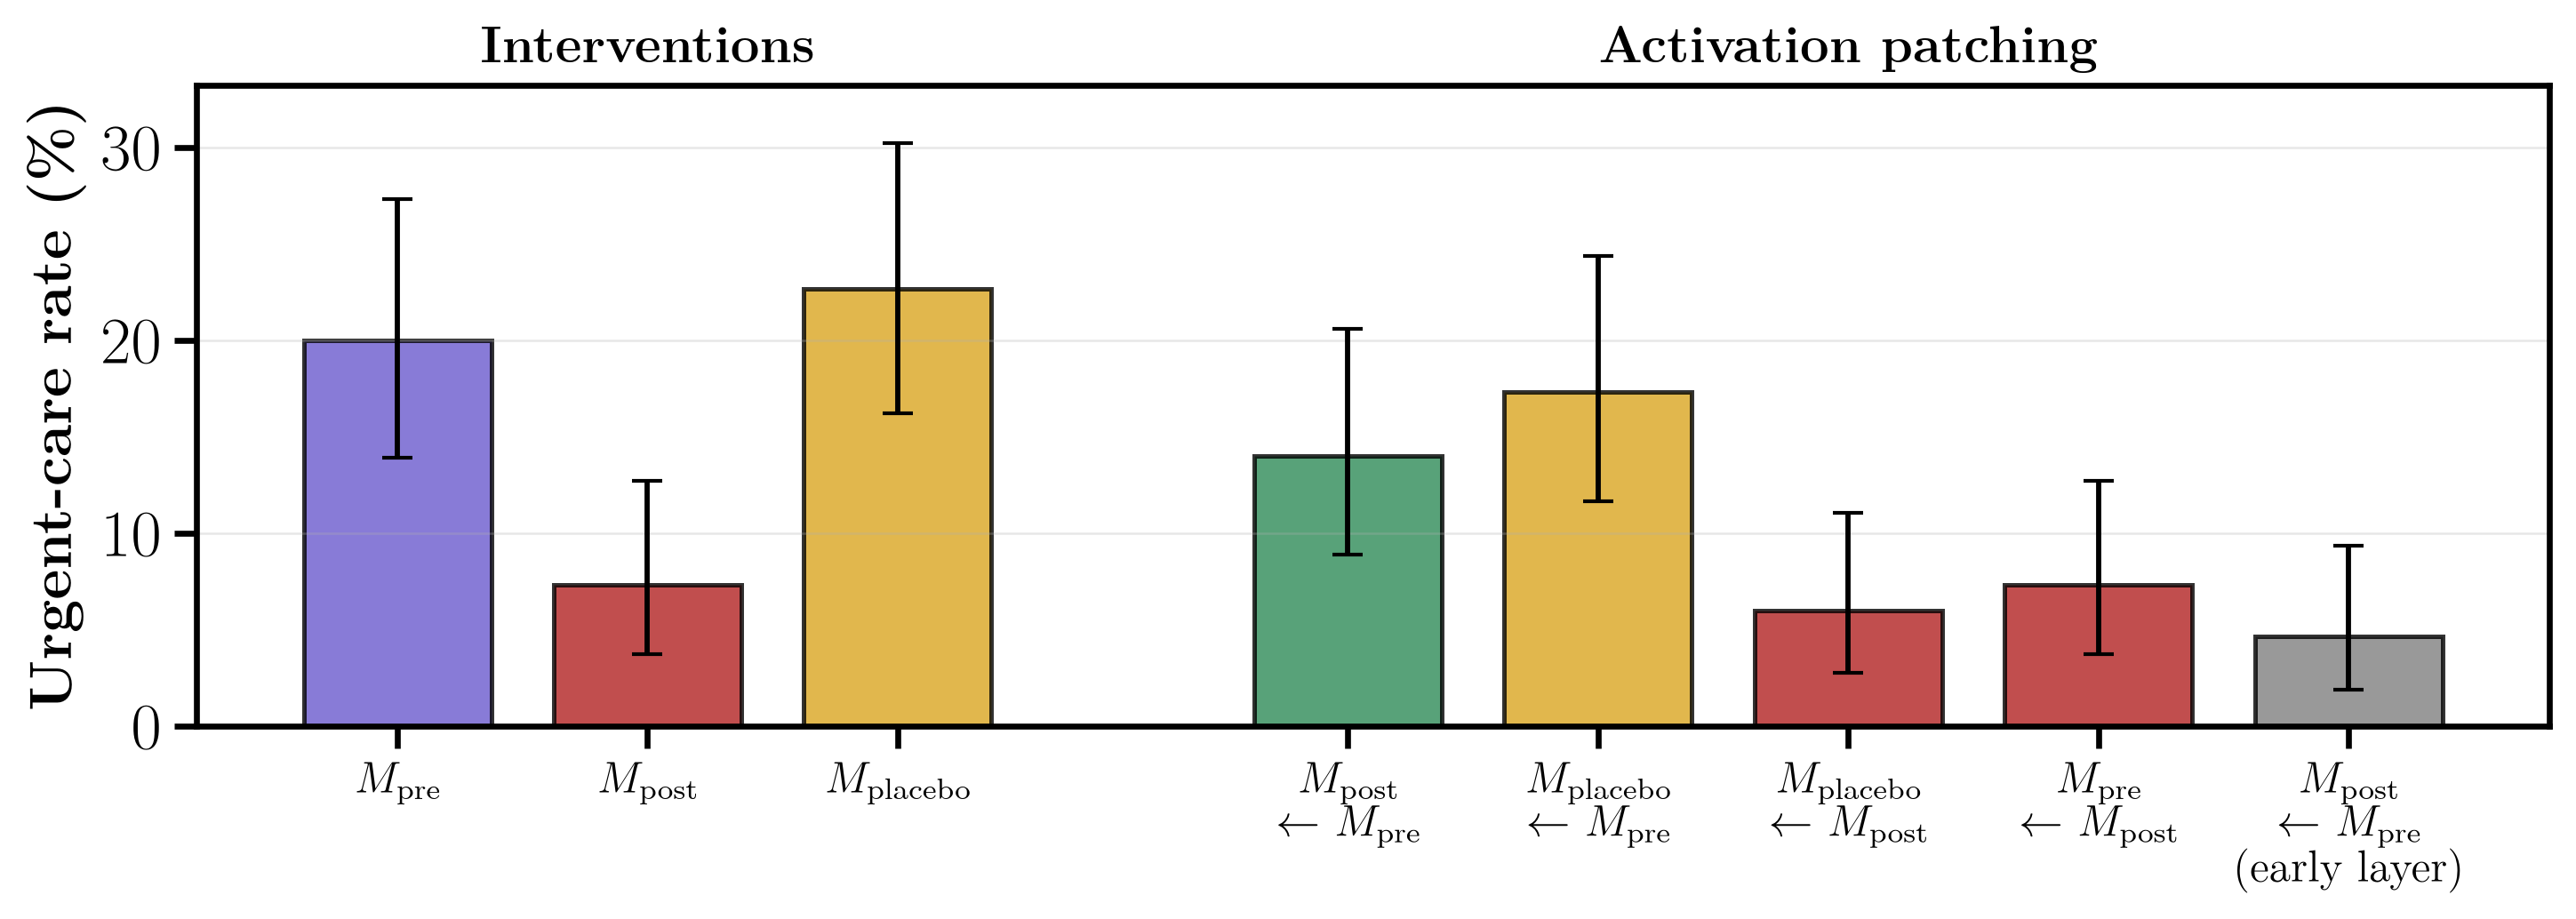

=== Llama-3.1-8B


saved results/figures/behavioral_shift_llama3.1-8b.pdf


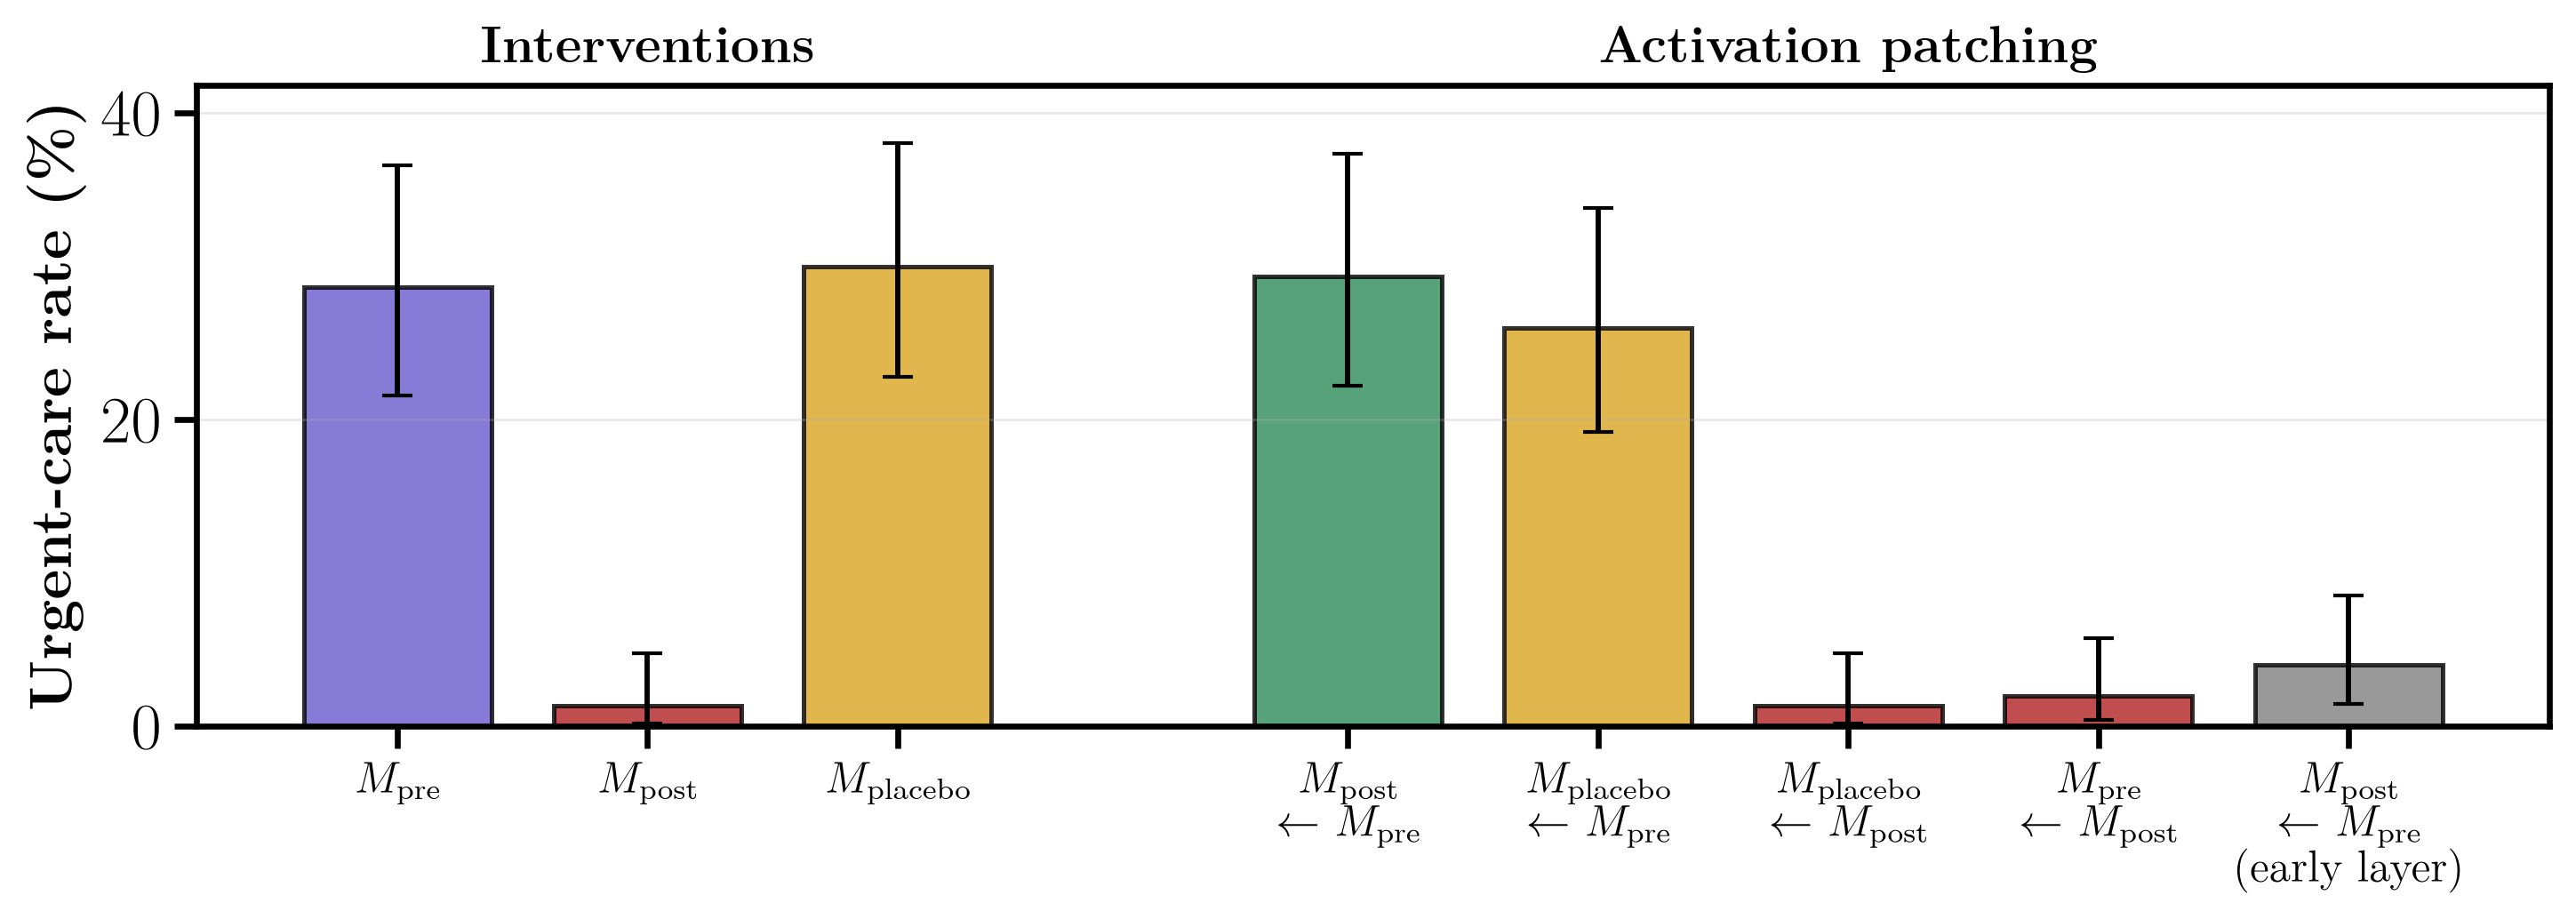

In [7]:
import matplotlib.pyplot as plt

from xai_delta import plotting

plotting.use_paper_style()
PRE, POST, PLA = plotting.PRE, plotting.POST, r"$M_{\mathrm{placebo}}$"
ARROW = r"$\leftarrow$"

for m in MODELS:
    y = Y[m]
    conditions = [
        (PRE, y["pre"], "slateblue"),
        (POST, y["post"], "firebrick"),
        (PLA, y["placebo"], "goldenrod"),
        (f"{POST}\n{ARROW} {PRE}", y["post_patched"], "seagreen"),
        (f"{PLA}\n{ARROW} {PRE}", y["placebo_patched"], "goldenrod"),
        (f"{PLA}\n{ARROW} {POST}", y["post_into_placebo"], "firebrick"),
        (f"{PRE}\n{ARROW} {POST}", y["reverse"], "firebrick"),
        (f"{POST}\n{ARROW} {PRE}\n(early layer)", y["offtarget"], "gray"),
    ]
    rates = [100 * v.mean() for _, v, _ in conditions]
    cis = [[100 * c for c in stats.clopper_pearson_ci(int(v.sum()), len(v))] for _, v, _ in conditions]

    print(f"=== {NAMES[m]}")
    fig, ax = plt.subplots(figsize=(10.0, 3.8), dpi=300)
    plotting.plot_rates_with_ci(ax, [c[0] for c in conditions], rates, cis, [c[2] for c in conditions],
                                groups=[("Interventions", 3), ("Activation patching", 5)])
    fig.tight_layout()
    path = config.FIGURES_DIR / f"behavioral_shift_{m}.pdf"
    config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, bbox_inches="tight")
    print(f"saved {path.relative_to(config.REPO_ROOT)}")
    plt.show()